# Week 11A: Visualizing large spatial datasets

We will use **Dask** to read data in partitions and **Datashader** to turn millions of points into images.

1. Map GPS point density and compare color scales.
2. Map Census categories.
3. Explore taxi trips over space and time.
4. Practice with Philadelphia parking records.

[Download notebook](lecture-11A.ipynb) · [Next lesson: LiDAR](lecture-11B.html)


## Before you start

Use **Python (largeviz)** for both lessons. Download [environment-viz.yml](environment-viz.yml) beside the notebooks. In a terminal opened in this lab folder:

```bash
# First time only:
conda env create -f environment-viz.yml
# If largeviz already exists, update it instead:
# conda env update -n largeviz -f environment-viz.yml
conda activate largeviz
python -m ipykernel install --user --name largeviz --display-name "Python (largeviz)"
jupyter lab
```

In VS Code, open the notebook and select **Python (largeviz)**. Run the cells from top to bottom. See the [README](README.md) for setup troubleshooting.


## Download the example data

Download the whole lab folder, or save these files in `data/samples/` beside this notebook:

- [OSM GPS points](data/samples/osm_sample.parquet)
- [Census dots](data/samples/census_sample.parquet)
- [Taxi trips](data/samples/taxi_sample.parquet)
- [Parking records](data/samples/parking_sample.csv)

These small teaching extracts let us practice the same workflow used for larger datasets. They are not representative population or travel estimates. Census dots are synthetic locations. See [data sources and sampling](data/samples/provenance.json).

## 1. Import the packages


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import datashader as ds
import datashader.transfer_functions as tf
from datashader.utils import lnglat_to_meters
from colorcet import fire
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Works from this lab folder or from the repository root.
LAB = Path.cwd()
if not (LAB / "data/samples").is_dir():
    LAB = LAB / "public/labs/week11-large-data-viz-lidar"
DATA = LAB / "data/samples"
OUT = LAB / "outputs/viz"
OUT.mkdir(parents=True, exist_ok=True)
if not (DATA / "osm_sample.parquet").is_file():
    raise FileNotFoundError("Download the whole lab folder, including data/samples, first.")
print("Datashader", ds.__version__, "| Dask", dask.__version__)

/opt/anaconda3/envs/largeviz/lib/python3.12/site-packages/datashader/__init__.py:6: FutureWarning: param.version.Version has been deprecated and will be removed in a future version.
  __version__ = str(param.version.Version(fpath=__file__, archive_commit="$Format:%h$",
/opt/anaconda3/envs/largeviz/lib/python3.12/site-packages/param/version.py:200: FutureWarning: param.version.run_cmd has been deprecated and will be removed in a future version.
  remotes = run_cmd([cmd, 'remote', '-v'],


Datashader 0.16.2 | Dask 2024.5.0


## 2. Read GPS points with Dask

`read_parquet()` creates a lazy table. `head()` reads a few rows so we can inspect the columns.


In [2]:
osm = dd.read_parquet(DATA / "osm_sample.parquet", columns=["x", "y"],
                      engine="pyarrow", split_row_groups=True)
print("Partitions:", osm.npartitions)
osm.head()

Partitions: 21


,x,y
0,-7000458.5,-9536415.0
1,-7141858.0,-9664043.0
2,-7379035.0,-9890349.0
3,-7721307.5,-10498321.0
4,-7514765.5,-7346013.0


### Count the points

Use `dask.compute()` to calculate several summaries in one pass. The full table stays partitioned.


In [3]:
row_count, mean_x, mean_y = dask.compute(osm.shape[0], osm.x.mean(), osm.y.mean())
print(f"Extract rows: {row_count:,}; mean x={mean_x:,.0f}, y={mean_y:,.0f} meters")

Extract rows: 1,000,050; mean x=2,731,821, y=5,801,809 meters


### Aggregate points into pixels

Create a canvas, then count how many points fall in each pixel. The coordinates are Web Mercator meters; convert the map extent from longitude/latitude.


In [4]:
def mercator_extent(lon_bounds, lat_bounds):
    x, y = lnglat_to_meters(lon_bounds, lat_bounds)
    return tuple(x), tuple(y)

world_x, world_y = mercator_extent((-180, 180), (-70, 80))
canvas = ds.Canvas(plot_width=900, plot_height=450, x_range=world_x, y_range=world_y)
osm_count = canvas.points(osm, "x", "y", agg=ds.count())
print("Aggregate dimensions:", dict(osm_count.sizes))
print("Points inside this extent:", int(osm_count.sum()))

Aggregate dimensions: {'y': 450, 'x': 900}
Points inside this extent: 1000049


### Compare color scales

Shade the same counts three ways. Log and equalized scales reveal sparse areas; they change how counts map to color.


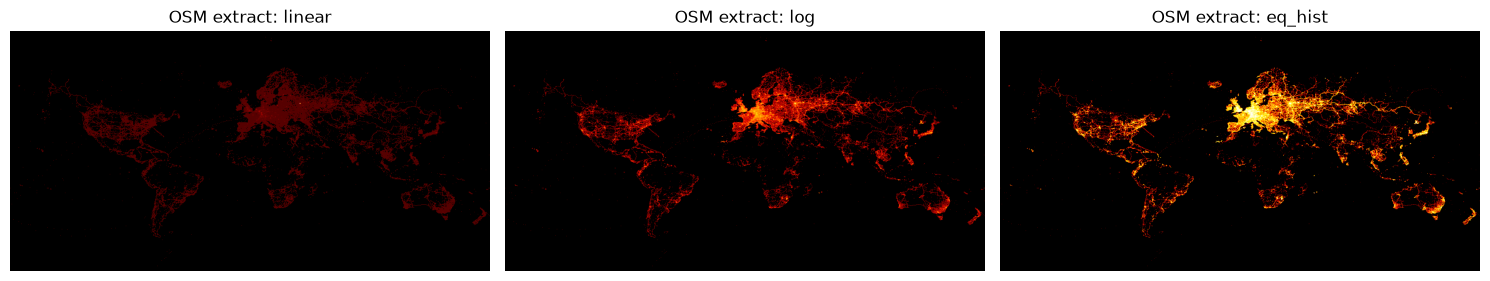

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, how in zip(axes, ["linear", "log", "eq_hist"]):
    image = tf.set_background(tf.shade(osm_count, cmap=fire[40:], how=how), "black")
    ax.imshow(image.to_pil())
    ax.set_title(f"OSM extract: {how}")
    ax.set_axis_off()
fig.tight_layout()
plt.show()

### Save a density map

Hide pixels with two or fewer points and save the image. Try a different threshold.


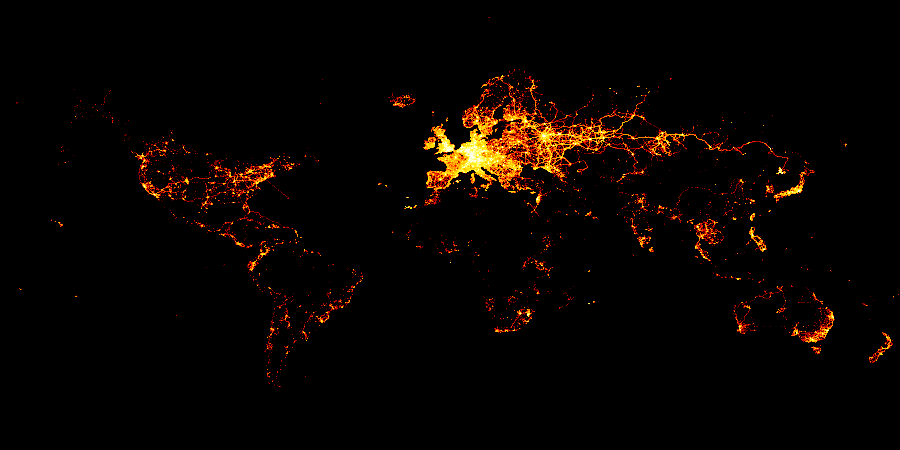

In [6]:
masked_osm = osm_count.where(osm_count > 2)
osm_image = tf.set_background(tf.shade(masked_osm, cmap=fire[40:], how="eq_hist"), "black")
osm_image.to_pil().save(OUT / "osm_density.png")
display(osm_image.to_pil())

## 3. Map Census categories

Read the Census extract and tell Datashader which categories to expect. `count_cat()` counts each category separately in every pixel. The labels come from the historical source data.


In [7]:
race_labels = {"w": "White", "b": "Black", "a": "Asian", "h": "Hispanic", "o": "Other"}
color_key = {"w": "#4cc9f0", "b": "#ffb703", "a": "#90be6d", "h": "#f28482", "o": "#cdb4db"}
census = dd.read_parquet(DATA / "census_sample.parquet", split_row_groups=True)
census["race"] = census["race"].astype(pd.CategoricalDtype(list(race_labels)))
census.head()

,easting,northing,race
0,-12352377.0,3676244.50,h
1,-12352691.0,3679306.75,h
2,-12352058.0,3677210.50,h
3,-12352007.0,3680322.75,h
4,-12351758.0,3677555.75,h


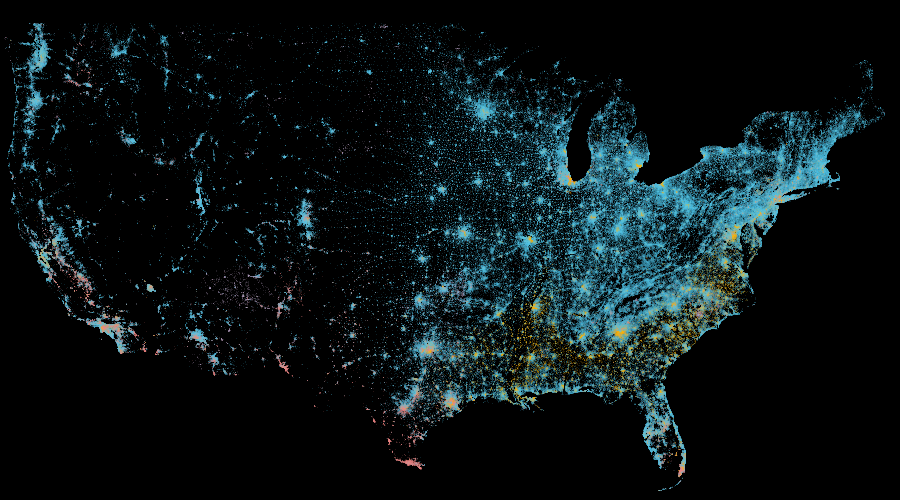

w       White
b       Black
a       Asian
h    Hispanic
o       Other
Name: Source category labels, dtype: object

In [8]:
usa_x, usa_y = mercator_extent((-125, -66), (24, 50))
census_canvas = ds.Canvas(plot_width=900, plot_height=500, x_range=usa_x, y_range=usa_y)
category_count = census_canvas.points(census, "easting", "northing", agg=ds.count_cat("race"))
census_image = tf.set_background(tf.shade(category_count, color_key=color_key, how="eq_hist"), "black")
display(census_image.to_pil())
pd.Series(race_labels, name="Source category labels")

## 4. Compare taxi pickups and dropoffs

Read the taxi extract and aggregate both locations on the same canvas. Subtract signed counts to show where pickups exceed dropoffs.


In [9]:
taxi = dd.read_parquet(DATA / "taxi_sample.parquet", split_row_groups=True)
NYC_X, NYC_Y = mercator_extent((-74.10, -73.70), (40.60, 40.90))
taxi_canvas = ds.Canvas(plot_width=750, plot_height=550, x_range=NYC_X, y_range=NYC_Y)
pickups = taxi_canvas.points(taxi, "pickup_x", "pickup_y", agg=ds.count()).rename({"pickup_x": "x", "pickup_y": "y"})
dropoffs = taxi_canvas.points(taxi, "dropoff_x", "dropoff_y", agg=ds.count()).rename({"dropoff_x": "x", "dropoff_y": "y"})
print("In-view pickups:", int(pickups.sum()), "| in-view dropoffs:", int(dropoffs.sum()))

In-view pickups: 149998 | in-view dropoffs: 149994


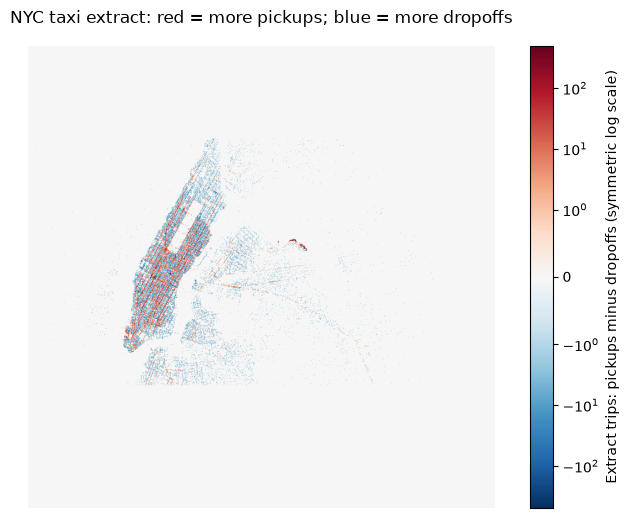

In [10]:
# Subtract signed values: unsigned subtraction would wrap below zero.
balance = pickups.astype("int64") - dropoffs.astype("int64")
from matplotlib.colors import SymLogNorm
limit = max(1, int(np.abs(balance).max()))
fig, ax = plt.subplots(figsize=(9, 6))
plot = ax.imshow(balance, origin="lower", cmap="RdBu_r", norm=SymLogNorm(linthresh=1, vmin=-limit, vmax=limit),
                 extent=[*NYC_X, *NYC_Y])
fig.colorbar(plot, ax=ax, label="Extract trips: pickups minus dropoffs (symmetric log scale)")
ax.set_title("NYC taxi extract: red = more pickups; blue = more dropoffs")
ax.set_axis_off()
plt.show()

### Summarize trips by weekday and hour

Compute a small summary table, then display it as a heatmap. These records cover part of January 2015.


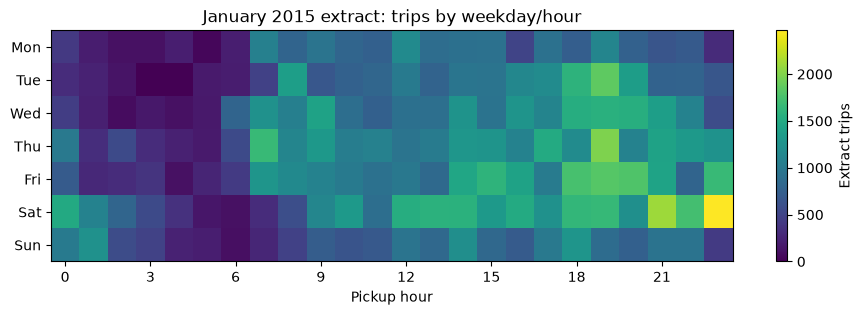

In [11]:
taxi["weekday"] = taxi.tpep_pickup_datetime.dt.dayofweek
hourly_table = taxi.groupby(["weekday", "pickup_hour"]).size().compute().unstack(fill_value=0)
hourly_table = hourly_table.reindex(index=range(7), columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3))
plot = ax.imshow(hourly_table, aspect="auto", cmap="viridis")
ax.set(yticks=range(7), yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
       xticks=range(0, 24, 3), xlabel="Pickup hour", title="January 2015 extract: trips by weekday/hour")
fig.colorbar(plot, ax=ax, label="Extract trips")
plt.show()

### Make a 24-hour animation

Count dropoffs by hour and save a GIF. Keep one color scale for every frame so the brightness is comparable.


In [12]:
taxi["dropoff_hour"] = taxi["dropoff_hour"].astype(pd.CategoricalDtype(list(range(24))))
by_hour = taxi_canvas.points(taxi, "dropoff_x", "dropoff_y", agg=ds.count_cat("dropoff_hour"))
max_count = max(2, int(by_hour.max()))
frames = []
from PIL import ImageDraw
for hour in range(24):
    image = tf.set_background(tf.shade(by_hour.sel(dropoff_hour=hour), cmap=fire[40:],
                                       how="log", span=(1, max_count)), "black").to_pil().convert("RGB")
    ImageDraw.Draw(image).text((16, 16), f"{hour:02d}:00 | historical taxi extract", fill="white")
    frames.append(image)
frames[0].save(OUT / "taxi_dropoffs_24h.gif", save_all=True, append_images=frames[1:],
               duration=250, loop=0)
display(HTML('<img src="outputs/viz/taxi_dropoffs_24h.gif" alt="24-hour taxi drop-off animation">'))

## 5. Practice: Philadelphia parking records

Read the CSV, remove missing or impossible coordinates, and project each partition to Web Mercator. Then make a density map.

**Try it:** change the map extent and image size. What changes about the visible pattern?


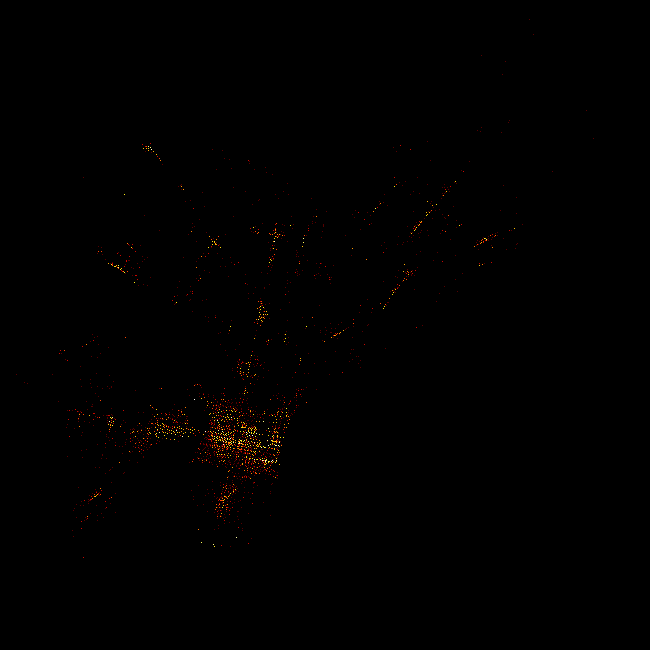

In [13]:
parking = dd.read_csv(DATA / "parking_sample.csv", dtype={"lat": "float64", "lon": "float64"})
parking = parking.dropna(subset=["lat", "lon"])
parking = parking[parking.lat.between(-85, 85) & parking.lon.between(-180, 180)]

def project_parking(partition):
    result = partition.copy()
    result["x"], result["y"] = lnglat_to_meters(result.lon.to_numpy(), result.lat.to_numpy())
    return result

meta = parking._meta.assign(x=pd.Series(dtype="float64"), y=pd.Series(dtype="float64"))
parking_xy = parking.map_partitions(project_parking, meta=meta)
philly_x, philly_y = mercator_extent((-75.28, -74.96), (39.86, 40.14))
parking_canvas = ds.Canvas(plot_width=650, plot_height=650, x_range=philly_x, y_range=philly_y)
parking_counts = parking_canvas.points(parking_xy, "x", "y", agg=ds.count())
parking_image = tf.set_background(tf.shade(parking_counts, cmap=fire[40:], how="eq_hist"), "black")
display(parking_image.to_pil())

## Try it yourself

1. Change the OSM canvas width to 450. What happens to detail?
2. Compare linear, log, and equalized colors. Which reveals sparse areas?
3. Change the taxi map extent. Do pickups still exceed dropoffs in the same places?

For a full dataset, point `dd.read_parquet()` at its local Parquet folder. Keep the same read → aggregate → shade workflow; avoid loading the entire table into pandas.
